# 文書要約のベースライン・抽象型要約・ROUGE とハルシネーション

書籍 第4章「言語生成問題の解き方」（4-1 文書要約：4-1-1, 4-1-2, 4-1-3, 4-1-4、図 4.5、関連論文 4章 5）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、以下の内容を体験します。

1. 要約の評価尺度 **ROUGE-1 / ROUGE-2 / ROUGE-L** の定義式からの実装と **書籍 図 4.5 (p.139) 手計算例の検証** (4-1-4)
2. 抽出型要約の代表手法（**リード法**・**TextRank**・**LexRank**）の実装と比較 (4-1-1, 4-1-2)
3. 記事構成（逆ピラミッド型 vs 後半結論型）による手法ごとの得意・不得意の分析
4. 複数文抽出 ($k=2$) における冗長性問題と **MMR (Maximal Marginal Relevance)** による多様性の確保 (4-1-2)
5. 抽象型（生成型）要約の仕組み：**Pointer-Generator（コピー機構）とカバレージ機構** の動作と反復抑制（4-1-3・関連論文 4章 5）
6. **抽象型要約におけるハルシネーションと ROUGE の限界**: 数値・極性誤りが高い ROUGE を出してしまう逆転現象と事実整合性チェック（4-1-3・4-1-4）

## 1. 準備とサンプル記事データの作成

日本語の文字単位（文字 n-gram）で評価・抽出を行うため、追加パッケージは不要で、標準ライブラリと `numpy`・`pandas`・`scikit-learn` のみで動作します。

In [1]:
import math
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ニュース記事風の「冒頭に結論がある記事（逆ピラミッド型）」と、解説・ブログ風の「中盤〜後半に結論がある記事」を混ぜた 6 本のサンプル記事（各 5 文）と人手参照要約を用意します。

In [2]:
articles = [
    {
        "id": 1,
        "type": "ニュース型（冒頭結論）",
        "sentences": [
            "政府は本日、AI分野の研究開発を支援する新たな補助金制度を来年度から開始すると発表しました。",
            "対象となるのは大学やスタートアップ企業で、最大で1件あたり5000万円が支給されます。",
            "近年、生成AIの急速な普及に伴い、国内での計算資源や人材の不足が課題となっていました。",
            "関係省庁は先月から有識者会議を開き、具体的な支援枠組みについて議論を重ねてきました。",
            "申請の受付は来年4月から開始される予定で、詳細は公式ウェブサイトで公開されます。",
        ],
        "reference": "政府は大学やスタートアップ向けに最大5000万円を支給するAI研究開発の新たな補助金制度を来年度から開始します。",
    },
    {
        "id": 2,
        "type": "ニュース型（冒頭結論）",
        "sentences": [
            "東京都内の主要鉄道各社は、来月1日から終電時刻を約15分繰り上げるダイヤ改正を実施します。",
            "これは深夜の保線作業の時間を確保し、作業員の負担を軽減することが主な目的です。",
            "対象となるのは山手線や中央線などの主要路線で、始発時刻に変更はありません。",
            "利用者の減少傾向も背景にあり、コロナ禍以降、深夜帯の乗車率は約3割低下していました。",
            "各社は駅構内のポスターやアプリを通じて、利用者への周知を進めています。",
        ],
        "reference": "都内の主要鉄道各社は深夜の保線作業時間確保のため、来月1日から終電を約15分繰り上げます。",
    },
    {
        "id": 3,
        "type": "ニュース型（冒頭結論）",
        "sentences": [
            "大手電機メーカーのA社は、従来比で充電時間を半分に短縮した新型バッテリーを開発しました。",
            "新開発の電極材料を採用することで、発熱を抑えながら急速充電を実現しています。",
            "同社は2年前から国立研究所と共同で次世代電池の基礎研究を進めてきました。",
            "この技術は電気自動車やスマートフォンへの応用が期待されており、年内の量産開始を目指します。",
            "発表を受けて、本日の株式市場ではA社の株価が一時5%上昇しました。",
        ],
        "reference": "A社が充電時間を半分に短縮した新型バッテリーを開発し、年内の量産開始を目指しています。",
    },
    {
        "id": 4,
        "type": "後半結論型（課題→調査→結論）",
        "sentences": [
            "私たちの街では近年、駅前商店街の空き店舗が増加していることが大きな悩みでした。",
            "以前は休日に多くの家族連れで賑わっていましたが、郊外に大型商業施設ができて状況が一変しました。",
            "市役所は現状を把握するため、住民2000人を対象に買い物行動に関するアンケート調査を実施しました。",
            "調査の結果、若年層は夜間の営業やカフェスペースの充実を求めていることが明らかになりました。",
            "これを受けて市は、空き店舗を改装したコワーキングスペースと夜カフェの誘致を最優先施策として決定しました。",
        ],
        "reference": "住民調査の結果を踏まえ、市は商店街の空き店舗にコワーキングスペースと夜カフェを誘致する施策を決定しました。",
    },
    {
        "id": 5,
        "type": "後半結論型（実験→比較→結論）",
        "sentences": [
            "自然言語処理のモデル開発では、最初から大規模な深層学習モデルを使うべきか議論になることがあります。",
            "大規模モデルは高い精度が期待できる一方、GPUコストや推論速度の面で運用が難しくなる場合があります。",
            "そこで今回、同じ文書分類データに対してルールベース、TF-IDF、BERTの3手法を比較実験しました。",
            "実験では1000件のサンプルデータを用い、正解率と推論時間、誤分類の傾向を詳しく分析しました。",
            "その結果、まずはTF-IDFなどの軽量なベースラインでデータ品質を確認してからBERTへ進むのが最も効率的だとわかりました。",
        ],
        "reference": "比較実験の結果、文書分類ではTF-IDFなどの軽量なベースラインでデータを確認してからBERTへ進むのが最も効率的だとわかりました。",
    },
    {
        "id": 6,
        "type": "後半結論型（背景→問題→結論）",
        "sentences": [
            "リモートワークが定着したことで、オンライン会議の回数が以前より大幅に増えています。",
            "会議の録音や議事録作成の負担を軽減するため、音声認識ツールの導入を検討する企業が増えました。",
            "しかし、専門用語や社内略語が多い会議では、汎用モデルそのままでは誤変換が多発してしまいます。",
            "実際に試したところ、固有名詞の誤認識が原因で議事録の手直しに多くの時間がかかりました。",
            "実用化には、社内の固有表現をユーザー辞書に登録し、さらに要約モデルで要点を整理する仕組みが不可欠です。",
        ],
        "reference": "オンライン会議の議事録自動化を実用化するには、社内固有名詞の辞書登録と要約モデルによる要点整理が不可欠です。",
    },
]
print(f"記事数: {len(articles)} 本")

記事数: 6 本


---

## 2. 評価尺度 ROUGE の実装（4-1-4「自動評価」）

文書要約では、参照要約に含まれる重要な情報（単語・フレーズ）をシステム要約がどれだけ**漏れなく拾えているか**（再現率; Recall）を重視する **ROUGE** が標準的に使われます。

- **ROUGE-1 / ROUGE-2**: 1-gram / 2-gram の重なりに基づく評価（日本語では文字 n-gram または単語 n-gram を用います。ここではトークナイザに依存しない文字 n-gram で計算します）
- **ROUGE-L**: 語順を保った最長共通部分列 (Longest Common Subsequence; **LCS**) の長さに基づく評価

ここでは ROUGE-1, ROUGE-2, ROUGE-L の F1 スコアを定義式から実装します。

In [3]:
def char_ngrams(text, n):
    t = text.replace(" ", "").replace("　", "")
    return [t[i:i + n] for i in range(len(t) - n + 1)]

def rouge_n_f1(hyp, ref, n=1):
    h_ng = Counter(char_ngrams(hyp, n))
    r_ng = Counter(char_ngrams(ref, n))
    overlap = sum(min(cnt, r_ng[g]) for g, cnt in h_ng.items())
    h_total = sum(h_ng.values())
    r_total = sum(r_ng.values())
    if overlap == 0 or h_total == 0 or r_total == 0:
        return 0.0
    prec = overlap / h_total
    rec = overlap / r_total
    return 2 * prec * rec / (prec + rec)

def lcs_length(a, b):
    '''動的計画法で文字列 a, b の最長共通部分列（LCS）の長さを求める'''
    m, n = len(a), len(b)
    dp = [0] * (n + 1)
    for i in range(m):
        prev = 0
        for j in range(n):
            temp = dp[j + 1]
            if a[i] == b[j]:
                dp[j + 1] = prev + 1
            else:
                dp[j + 1] = max(dp[j + 1], dp[j])
            prev = temp
    return dp[n]

def rouge_l_f1(hyp, ref):
    h = hyp.replace(" ", "").replace("　", "")
    r = ref.replace(" ", "").replace("　", "")
    if not h or not r:
        return 0.0
    lcs = lcs_length(h, r)
    if lcs == 0:
        return 0.0
    prec = lcs / len(h)
    rec = lcs / len(r)
    return 2 * prec * rec / (prec + rec)

print("ROUGE-1:", round(rouge_n_f1("政府はAIの補助金を開始します", "政府はAI研究開発の補助金を開始します", 1), 3))
print("ROUGE-L:", round(rouge_l_f1("政府はAIの補助金を開始します", "政府はAI研究開発の補助金を開始します"), 3))

ROUGE-1: 0.882
ROUGE-L: 0.882


### 書籍 図 4.5 (p.139) の単語単位 ROUGE-1 / ROUGE-L 手計算例をコードで検証する

書籍 図 4.5 (p.139) では、英語の単語列を例に次の出力文と参照文に対する ROUGE-1 と ROUGE-L（最長共通部分列 `"of people"`）が計算されています。

- 出力文: `"a lot of people are in Kyoto"`（7 語）
- 参照文: `"Kyoto is full of people"`（5 語）

単語単位の定義式から計算し、図 4.5 の数値 (ROUGE-1: Recall $3/5=0.600$, Precision $3/7 \approx 0.429$, F1 $=0.500$; ROUGE-L: Recall $2/5=0.400$, Precision $2/7 \approx 0.286$, F1 $=1/3 \approx 0.333$) と一致することを確認しましょう。

In [4]:
def word_rouge_1_prf(hyp, ref):
    hw, rw = hyp.split(), ref.split()
    ch, cr = Counter(hw), Counter(rw)
    overlap = sum(min(c, cr[w]) for w, c in ch.items())
    prec = overlap / len(hw)
    rec = overlap / len(rw)
    f1 = 2 * prec * rec / (prec + rec)
    return overlap, len(hw), len(rw), prec, rec, f1

def word_rouge_l_prf(hyp, ref):
    hw, rw = hyp.split(), ref.split()
    lcs = lcs_length(hw, rw)
    prec = lcs / len(hw)
    rec = lcs / len(rw)
    f1 = 2 * prec * rec / (prec + rec)
    return lcs, len(hw), len(rw), prec, rec, f1

hyp_fig45 = "a lot of people are in Kyoto"
ref_fig45 = "Kyoto is full of people"

o1, lh1, lr1, p1, r1, f1_1 = word_rouge_1_prf(hyp_fig45, ref_fig45)
ol, lhl, lrl, pl, rl, f1_l = word_rouge_l_prf(hyp_fig45, ref_fig45)

fig45_df = pd.DataFrame([
    {"指標": "ROUGE-1", "一致数/LCS長": f"{o1} 語", "Recall": f"{o1}/{lr1} = {r1:.3f}", "Precision": f"{o1}/{lh1} = {p1:.3f}", "F1": round(f1_1, 3)},
    {"指標": "ROUGE-L", "一致数/LCS長": f"{ol} 語 ('of people')", "Recall": f"{ol}/{lrl} = {rl:.3f}", "Precision": f"{ol}/{lhl} = {pl:.3f}", "F1": round(f1_l, 3)},
])
display(fig45_df)

,指標,一致数/LCS長,Recall,Precision,F1
0,ROUGE-1,3 語,3/5 = 0.600,3/7 = 0.429,0.500
1,ROUGE-L,2 語 ('of people'),2/5 = 0.400,2/7 = 0.286,0.333


---

## 3. 抽出型要約の 3 手法を実装・比較する (4-1-1, 4-1-2)

記事の 5 文から **要約として 1 文** を抽出するタスクとして、書籍 4-1-1 / 4-1-2 (p.131) で解説されている次の 3 手法を比較します。

1. **リード法 (Lead)**: 常に先頭の 1 文目を選ぶ単純なベースライン
2. **TextRank**: 2 文間の共通要素数に基づく類似度 $\mathrm{Sim}(S_i, S_j) = \frac{|\{w_k \mid w_k \in S_i \ \& \ w_k \in S_j\}|}{\log(|S_i|) + \log(|S_j|)}$ を用いて PageRank（べき乗法）で中心文を選ぶ
   この演習の TextRank では、各文を重複を除いた文字バイグラムの集合として表し、式の分母に使う各集合の要素数は最低2とします。
3. **LexRank**: TF-IDF（文字 2〜3-gram）のコサイン類似度行列を用いて PageRank（べき乗法）で中心文を選ぶ

In [5]:
def pagerank_select(sim, sentences, k=1, damping=0.85, n_iter=30):
    np.fill_diagonal(sim, 0.0)
    row_sums = sim.sum(axis=1, keepdims=True)
    trans = np.divide(sim, row_sums, out=np.full_like(sim, 1.0 / len(sentences)), where=row_sums != 0)
    scores = np.ones(len(sentences)) / len(sentences)
    for _ in range(n_iter):
        scores = (1.0 - damping) / len(sentences) + damping * trans.T @ scores
    top_idx = sorted(np.argsort(scores)[::-1][:k])
    return "".join(sentences[i] for i in top_idx)

def summarize_lead(sentences, k=1):
    return "".join(sentences[:k])

def summarize_textrank(sentences, k=1):
    # 書籍 p.131 の TextRank 類似度（共通バイグラム数 / (log|Si| + log|Sj|)）
    sets = [set(char_ngrams(s, 2)) for s in sentences]
    n = len(sentences)
    sim = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i != j:
                denom = math.log(max(len(sets[i]), 2)) + math.log(max(len(sets[j]), 2))
                sim[i, j] = len(sets[i] & sets[j]) / denom
    return pagerank_select(sim, sentences, k=k)

def summarize_lexrank(sentences, k=1):
    # 書籍 p.131 の LexRank 類似度（TF-IDF のコサイン類似度）
    vec = TfidfVectorizer(analyzer="char", ngram_range=(2, 3))
    mat = vec.fit_transform(sentences)
    sim = cosine_similarity(mat)
    return pagerank_select(sim, sentences, k=k)

methods = {
    "リード法": summarize_lead,
    "TextRank": summarize_textrank,
    "LexRank": summarize_lexrank,
}

eval_rows = []
for art in articles:
    for m_name, fn in methods.items():
        hyp = fn(art["sentences"], k=1)
        eval_rows.append({
            "記事ID": art["id"],
            "構成タイプ": art["type"],
            "手法": m_name,
            "ROUGE-1": round(rouge_n_f1(hyp, art["reference"], 1), 3),
            "ROUGE-2": round(rouge_n_f1(hyp, art["reference"], 2), 3),
            "ROUGE-L": round(rouge_l_f1(hyp, art["reference"]), 3),
            "抽出された文": hyp,
        })

res_df = pd.DataFrame(eval_rows)
print("=== 全記事の平均 ROUGE スコア ===")
display(res_df.groupby("手法")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean().round(3))

print("\n=== 記事の構成タイプ別の平均 ROUGE-L ===")
display(res_df.pivot_table(index="構成タイプ", columns="手法", values="ROUGE-L", aggfunc="mean").round(3))

=== 全記事の平均 ROUGE スコア ===


,ROUGE-1,ROUGE-2,ROUGE-L
手法,,,
LexRank,0.449,0.255,0.340
TextRank,0.563,0.393,0.489
リード法,0.515,0.343,0.431



=== 記事の構成タイプ別の平均 ROUGE-L ===


手法,LexRank,TextRank,リード法
構成タイプ,,,
ニュース型（冒頭結論）,0.351,0.465,0.620
後半結論型（実験→比較→結論）,0.342,0.891,0.191
後半結論型（背景→問題→結論）,0.280,0.280,0.232
後半結論型（課題→調査→結論）,0.367,0.367,0.304


### 記事ごとの抽出結果を確認する

スコアだけでなく、実際にどの文が選ばれたかを参照要約と見比べてみましょう。

In [6]:
for art in articles:
    print(f"[記事 {art['id']}: {art['type']}]")
    print(f"  参照要約: {art['reference']}")
    sub = res_df[res_df["記事ID"] == art["id"]]
    for _, row in sub.iterrows():
        print(f"  {row['手法']:8s} (R-L={row['ROUGE-L']:.3f}): {row['抽出された文']}")
    print()

[記事 1: ニュース型（冒頭結論）]
  参照要約: 政府は大学やスタートアップ向けに最大5000万円を支給するAI研究開発の新たな補助金制度を来年度から開始します。
  リード法     (R-L=0.549): 政府は本日、AI分野の研究開発を支援する新たな補助金制度を来年度から開始すると発表しました。
  TextRank (R-L=0.549): 政府は本日、AI分野の研究開発を支援する新たな補助金制度を来年度から開始すると発表しました。
  LexRank  (R-L=0.208): 申請の受付は来年4月から開始される予定で、詳細は公式ウェブサイトで公開されます。

[記事 2: ニュース型（冒頭結論）]
  参照要約: 都内の主要鉄道各社は深夜の保線作業時間確保のため、来月1日から終電を約15分繰り上げます。
  リード法     (R-L=0.689): 東京都内の主要鉄道各社は、来月1日から終電時刻を約15分繰り上げるダイヤ改正を実施します。
  TextRank (R-L=0.225): 各社は駅構内のポスターやアプリを通じて、利用者への周知を進めています。
  LexRank  (R-L=0.225): 各社は駅構内のポスターやアプリを通じて、利用者への周知を進めています。

[記事 3: ニュース型（冒頭結論）]
  参照要約: A社が充電時間を半分に短縮した新型バッテリーを開発し、年内の量産開始を目指しています。
  リード法     (R-L=0.621): 大手電機メーカーのA社は、従来比で充電時間を半分に短縮した新型バッテリーを開発しました。
  TextRank (R-L=0.621): 大手電機メーカーのA社は、従来比で充電時間を半分に短縮した新型バッテリーを開発しました。
  LexRank  (R-L=0.621): 大手電機メーカーのA社は、従来比で充電時間を半分に短縮した新型バッテリーを開発しました。

[記事 4: 後半結論型（課題→調査→結論）]
  参照要約: 住民調査の結果を踏まえ、市は商店街の空き店舗にコワーキングスペースと夜カフェを誘致する施策を決定しました。
  リード法     (R-L=0.304): 私たちの街では近年、駅前商店街の空き店舗が増加していることが大きな悩みでした。
  TextRank (

### 観察とまとめ

1. **ニュース型（冒頭結論）ではリード法が非常に強い**: 新聞・ニュース記事は最初の文に要点をまとめる慣習（逆ピラミッド構造）があるため、単純なリード法が強力なベースラインになります（書籍 4-1-1）。
2. **後半結論型では内容ベースの手法が有利**: 課題や実験の経緯を述べてから最後に結論を書く構成では、リード法は導入文を選んでしまいますが、TextRank や LexRank は記事全体のキーワードが集約された文を拾えることがあります。
3. **抽出型要約の限界**: 抽出型要約は文をそのままコピーするため文法的な破綻は起きにくい一方、参照要約のように複数の文の要素を 1 文に圧縮・言い換えすること（**抽象型要約**）はできません。

---

## 4. 複数文抽出 ($k=2$) の冗長性問題と MMR (4-1-2)

第 3 節では 1 文だけを抽出しましたが、実際の要約では複数の文（例：$k=2$）を抜き出すことがよくあります。このとき、記事内に**同じ見出し内容を少し言い換えて繰り返す文**（例：文1 と 文2）が含まれると、互いに高い類似度を持つため両方の重要度スコアが高くなり、通常の LexRank（上位 $k$ 文選択）は**内容が重複した冗長な 2 文**（文1 + 文2）を選んでしまいます。

この冗長性を抑える手法が **MMR (Maximal Marginal Relevance)** です。各文 $s_i$ の重要度 $\mathrm{Rel}(s_i)$（ここでは最大値で 0〜1 に正規化した LexRank スコア）から、すでに選択した文集合 $S$ との最大類似度（文字 2〜3-gram TF-IDF コサイン類似度）をペナルティとして差し引きながら 1 文ずつ貪欲に選びます。

$$\mathrm{MMR}(s_i) = \lambda \cdot \mathrm{Rel}(s_i) - (1 - \lambda) \max_{s_j \in S} \mathrm{Sim}(s_i, s_j)$$

ここでは $\lambda = 0.6$ とし（$\lambda = 1.0$ のときは通常の LexRank と一致）、見出しの言い換えが重複する 3 本のニュース記事（各 6 文、2 文の参照要約付き）で通常の LexRank ($k=2$) と MMR ($k=2$) を比較します。

In [7]:
mmr_articles = [
    {
        "id": 1,
        "title": "自治体DX補助金制度",
        "sentences": [
            "総務省は本日、全国の自治体で行政手続きのオンライン化と窓口業務のデジタル化を支援する新たな補助金制度を来年度から開始すると発表しました。",
            "来年度から開始される総務省の新たな補助金制度は、全国の自治体における窓口業務のデジタル化と行政手続きのオンライン化を支援するものです。",
            "これまで各地では申請書類の紙処理や窓口対応の負担が課題で、予算措置による早期の事務効率化が求められていました。",
            "政府の検討会議でも、来月15日からの申請受付や1件あたり最大3000万円の上限額など交付基準の枠組みを詰めてきました。",
            "今回の予算総額は120億円で、来月15日から申請を受け付け、採択自治体へ1件あたり最大3000万円を交付する計画です。",
            "なお、採択自治体の公表や交付金の詳しい申請方法については、来週公開される特設サイトで確認できます。",
        ],
        "reference": "総務省は全国の自治体で手続きオンライン化と窓口のデジタル化を支援する新補助金制度を来年度から始めます。総予算120億円で来月15日から申請を受け付け、1件最大3000万円を交付します。",
    },
    {
        "id": 2,
        "title": "自動運転バス実証実験",
        "sentences": [
            "国土交通省と北九州市は本日、市内中心部の幹線道路で自動運転バスの定期運行を行う実証実験を今年秋から開始すると発表しました。",
            "今年秋から開始される実証実験は、国土交通省と北九州市が市内中心部の幹線道路で自動運転バスの定期運行を行うものです。",
            "地方都市では路線バスの運転手不足が進んでおり、利用しやすい予約導線と安定した運行ダイヤの維持が課題となっていました。",
            "運行開始に向けて、導入車両には周囲の障害物を検知する最新センサーを搭載し、専用アプリによる事前予約や安全確認テストを重ねています。",
            "車両には最新センサーを搭載し、利用者は専用アプリから無料で予約でき、1日あたり12便を運行する予定です。",
            "乗客が専用アプリで無料予約できる1日12便の運行データは来春までに集計され、今後の本格展開に活用されます。",
        ],
        "reference": "国交省と北九州市は今年秋から市内幹線道路で自動運転バスの定期運行実験を始めます。最新センサー搭載車両を用い、専用アプリから無料予約できて1日12便を運行する予定です。",
    },
    {
        "id": 3,
        "title": "全固体電池の量産技術開発",
        "sentences": [
            "自動車大手のA社は本日、電気自動車向けに充電時間を従来の半分へ短縮する新型全固体電池の量産技術を確立したと発表しました。",
            "A社が確立した新たな量産技術は、電気自動車向けの新型全固体電池において充電時間を従来の半分へ短縮するものです。",
            "従来の車載電池は急速充電時の発熱が障壁でしたが、材料改良によって高い耐久性と生産効率を両立させました。",
            "すでに栃木工場での試作ライン検証を終えており、月産1万台規模の生産体制と800キロメートル走行の目標達成にめどを付けました。",
            "来年春から栃木工場で月産1万台分の生産を始め、1回の充電で800キロメートル走れる新型車へ搭載する計画です。",
            "なお、新型車の販売価格帯や予約受付の時期については、来月開かれる事業説明会で公表する予定です。",
        ],
        "reference": "A社は充電時間を半減するEV向け新型全固体電池の量産技術を確立しました。来春から栃木工場で月産1万台を生産し、1充電で800キロ走れる新型車へ搭載します。",
    },
]

def compute_lexrank(sentences, damping=0.85, n_iter=30):
    vec = TfidfVectorizer(analyzer="char", ngram_range=(2, 3))
    mat = vec.fit_transform(sentences)
    sim = cosine_similarity(mat)
    sim_pr = sim.copy()
    np.fill_diagonal(sim_pr, 0.0)
    row_sums = sim_pr.sum(axis=1, keepdims=True)
    trans = np.divide(sim_pr, row_sums, out=np.full_like(sim_pr, 1.0 / len(sentences)), where=row_sums != 0)
    scores = np.ones(len(sentences)) / len(sentences)
    for _ in range(n_iter):
        scores = (1.0 - damping) / len(sentences) + damping * trans.T @ scores
    return scores, sim

def select_mmr(sentences, k=2, lam=0.6):
    scores, sim = compute_lexrank(sentences)
    rel = scores / scores.max()
    selected = []
    remaining = list(range(len(sentences)))
    while len(selected) < k and remaining:
        if not selected:
            best = max(remaining, key=lambda i: rel[i])
        else:
            best = max(
                remaining,
                key=lambda i: lam * rel[i] - (1.0 - lam) * max(sim[i, j] for j in selected),
            )
        selected.append(best)
        remaining.remove(best)
    idx = sorted(selected)
    return idx, "".join(sentences[i] for i in idx), rel, sim

# 記事 1 について 2 文目選択時の MMR スコア内訳を確認
art1 = mmr_articles[0]
_, _, rel1, sim1 = select_mmr(art1["sentences"], k=2, lam=0.6)
first1 = int(np.argmax(rel1))
breakdown_rows = []
for i, sent in enumerate(art1["sentences"]):
    mmr_s = None if i == first1 else round(float(0.6 * rel1[i] - 0.4 * sim1[i, first1]), 3)
    breakdown_rows.append({
        "文番号": f"文{i + 1}",
        "正規化 LexRank 中心性 Rel": round(float(rel1[i]), 3),
        f"文{first1 + 1}との類似度 Sim": round(float(sim1[i, first1]), 3),
        "2文目 MMR スコア (λ=0.6)": "選択済み(1文目)" if mmr_s is None else mmr_s,
        "文（冒頭）": sent[:32] + "…",
    })
print("=== 記事 1（自治体DX補助金制度）の 2 文目選択スコア内訳 ===")
display(pd.DataFrame(breakdown_rows))

mmr_rows = []
for art in mmr_articles:
    idx_lr, hyp_lr, _, _ = select_mmr(art["sentences"], k=2, lam=1.0)
    idx_mmr, hyp_mmr, _, _ = select_mmr(art["sentences"], k=2, lam=0.6)
    for m_name, idx, hyp in [
        ("LexRank (k=2)", idx_lr, hyp_lr),
        ("MMR (λ=0.6, k=2)", idx_mmr, hyp_mmr),
    ]:
        mmr_rows.append({
            "記事": f"{art['id']}. {art['title']}",
            "手法": m_name,
            "選択された文": "+".join(f"文{i + 1}" for i in idx),
            "ROUGE-1": round(rouge_n_f1(hyp, art["reference"], 1), 3),
            "ROUGE-2": round(rouge_n_f1(hyp, art["reference"], 2), 3),
            "ROUGE-L": round(rouge_l_f1(hyp, art["reference"]), 3),
        })

mmr_df = pd.DataFrame(mmr_rows)
print("\n=== 記事別の複数文抽出 (k=2) 比較 ===")
display(mmr_df)

print("\n=== 平均 ROUGE スコア（3記事平均） ===")
display(mmr_df.groupby("手法")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean().round(3))

print("\n=== 記事 1 の出力例比較 ===")
print("参照要約         :", art1["reference"])
print("LexRank (k=2)    :", select_mmr(art1["sentences"], k=2, lam=1.0)[1])
print("MMR (λ=0.6, k=2) :", select_mmr(art1["sentences"], k=2, lam=0.6)[1])

=== 記事 1（自治体DX補助金制度）の 2 文目選択スコア内訳 ===


,文番号,正規化 LexRank 中心性 Rel,文1との類似度 Sim,2文目 MMR スコア (λ=0.6),文（冒頭）
0,文1,1.000,1.000,選択済み(1文目),総務省は本日、全国の自治体で行政手続きのオンライン化と窓口業務の…
1,文2,0.996,0.567,0.37,来年度から開始される総務省の新たな補助金制度は、全国の自治体にお…
2,文3,0.223,0.028,0.122,これまで各地では申請書類の紙処理や窓口対応の負担が課題で、予算措…
3,文4,0.670,0.027,0.391,政府の検討会議でも、来月15日からの申請受付や1件あたり最大30…
4,文5,0.795,0.024,0.468,今回の予算総額は120億円で、来月15日から申請を受け付け、採択…
5,文6,0.339,0.011,0.199,なお、採択自治体の公表や交付金の詳しい申請方法については、来週公…



=== 記事別の複数文抽出 (k=2) 比較 ===


,記事,手法,選択された文,ROUGE-1,ROUGE-2,ROUGE-L
0,1. 自治体DX補助金制度,LexRank (k=2),文1+文2,0.546,0.382,0.493
1,1. 自治体DX補助金制度,"MMR (λ=0.6, k=2)",文1+文5,0.822,0.673,0.795
2,2. 自動運転バス実証実験,LexRank (k=2),文1+文2,0.527,0.332,0.408
3,2. 自動運転バス実証実験,"MMR (λ=0.6, k=2)",文1+文5,0.816,0.608,0.714
4,3. 全固体電池の量産技術開発,LexRank (k=2),文1+文2,0.510,0.326,0.406
5,3. 全固体電池の量産技術開発,"MMR (λ=0.6, k=2)",文1+文5,0.754,0.614,0.712



=== 平均 ROUGE スコア（3記事平均） ===


,ROUGE-1,ROUGE-2,ROUGE-L
手法,,,
LexRank (k=2),0.528,0.347,0.436
"MMR (λ=0.6, k=2)",0.797,0.632,0.740



=== 記事 1 の出力例比較 ===
参照要約         : 総務省は全国の自治体で手続きオンライン化と窓口のデジタル化を支援する新補助金制度を来年度から始めます。総予算120億円で来月15日から申請を受け付け、1件最大3000万円を交付します。
LexRank (k=2)    : 総務省は本日、全国の自治体で行政手続きのオンライン化と窓口業務のデジタル化を支援する新たな補助金制度を来年度から開始すると発表しました。来年度から開始される総務省の新たな補助金制度は、全国の自治体における窓口業務のデジタル化と行政手続きのオンライン化を支援するものです。
MMR (λ=0.6, k=2) : 総務省は本日、全国の自治体で行政手続きのオンライン化と窓口業務のデジタル化を支援する新たな補助金制度を来年度から開始すると発表しました。今回の予算総額は120億円で、来月15日から申請を受け付け、採択自治体へ1件あたり最大3000万円を交付する計画です。


3 本すべての記事で次の現象が確認できます。

- **通常の LexRank ($k=2$)**: 見出しを言い換えた文 1 と文 2 が互いの中心性を押し上げるため、**内容が重複する `文1+文2`** を選んでしまい、予算規模・実施時刻・生産台数といった具体的な補足情報を取りこぼします。
- **MMR ($\lambda = 0.6, k=2$)**: 1 文目に文 1 を選んだあと、文 1 とのコサイン類似度が高い文 2 には大きな冗長性ペナルティ（記事 1 では $\mathrm{Sim}=0.567$）がかかるため、類似度が低く中心性も高い具体的な事実の文（**`文1+文5`**）が選ばれます。その結果、3 記事すべてで ROUGE-1 / ROUGE-2 / ROUGE-L が大きく向上しています。

---

## 5. 抽象型（生成型）要約の仕組み：Pointer-Generator（コピー機構）とカバレージ機構（4-1-3・関連論文 4章 5）

第 3〜4 節の抽出型要約に対し、書籍 4-1-3 および関連論文 4章 5（See et al., ACL 2017「*Get To The Point: Summarization with Pointer-Generator Networks*」）の **抽象型（生成型）要約** では、固定語彙から新しい表現を生成しつつ、原文の固有名詞や数値など未知語 (OOV) をそのままコピーして補います。

**Pointer-Generator** では時刻 $t$ のアテンション分布 $\mathbf{a}^t$ とコンテキストベクトル $\mathbf{h}_t^* = \sum_i a_i^t \mathbf{h}_i$ から生成確率 $p_{\text{gen}} \in [0, 1]$ を求め、固定語彙確率 $P_{\text{vocab}}(w)$ とコピー確率をブレンドします。

$$P(w) = p_{\text{gen}} P_{\text{vocab}}(w) + (1 - p_{\text{gen}}) \sum_{i: w_i = w} a_i^t$$

さらに **カバレージ機構 (Coverage)** では過去の累積アテンション $c_i^t = \sum_{t' < t} a_i^{t'}$ をアテンション計算 $e_i^t$ へのペナルティ ($-w_c c_i^t$) として組み込み、同じ原文箇所の繰り返し参照を防ぎます。OOV 固有名詞・数値（`A社`, `栃木工場`, `全固体電池`, `5000万円`, `月産1万台`）を含む記事で次の 3 条件を比較しましょう。
1. **語彙生成のみ ($p_{\text{gen}} = 1$)**: OOV が `<unk>` に潰れる。
2. **コピー機構あり・カバレージなし ($w_c = 0$)**: OOV をコピーできるが同じフレーズを反復ループする。
3. **Pointer-Generator + カバレージ ($w_c > 0$)**: OOV をコピーしつつ重複なく要約を完結させる。

1) 語彙生成のみ (コピーなし)        : 同社は<unk>で新技術を開発し、<unk>の補助金で<unk>の量産を始める
2) コピー機構あり・カバレージなし   : A社は栃木工場で全固体電池を開発し、栃木工場で全固体電池を開発し、栃木工場で全固体電池
3) Pointer-Generator + カバレージ   : A社は栃木工場で全固体電池を開発し、5000万円の補助金で月産1万台の量産を始める

=== (3) Pointer-Generator + カバレージのステップ別生成とコピー率 ===


,ステップ,生成語,p_gen,コピー率 (1-p_gen),最大注目原文語,OOV
0,1,A社,0.132,0.868,A社,○
1,2,は,0.846,0.154,は,
2,3,栃木工場,0.129,0.871,栃木工場,○
3,4,で,0.853,0.147,で,
4,5,全固体電池,0.125,0.875,全固体電池,○
5,6,を,0.855,0.145,を,
6,7,開発,0.852,0.148,開発,
7,8,し,0.852,0.148,し,
8,9,、,0.852,0.148,、,
9,10,5000万円,0.113,0.887,5000万円,○


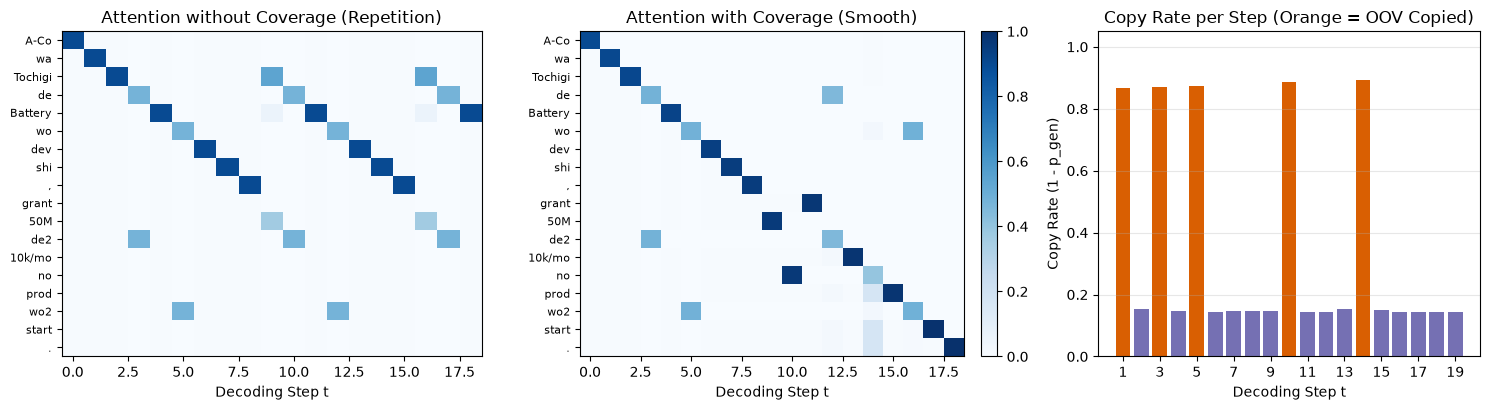

In [8]:
import matplotlib.pyplot as plt

source_tokens = [
    "A社", "は", "栃木工場", "で", "全固体電池", "を", "開発", "し", "、",
    "補助金", "5000万円", "で", "月産1万台", "の", "量産", "を", "始める", "。",
]
# 固定デコーダ語彙（A社・栃木工場・全固体電池・5000万円・月産1万台 は OOV として含まれない）
fixed_vocab = [
    "<unk>", "<eos>", "は", "で", "を", "の", "、", "。",
    "同社", "新技術", "開発", "し", "補助金", "活用", "量産", "始める",
]

concepts = [
    "ORG", "TOPIC_P", "LOC", "LOC_P", "TECH", "OBJ_P", "DEV", "CONJ_S",
    "COMMA", "GRANT", "AMT", "NO_P", "VOL", "MASS", "START", "EOS",
]
C_IDX = {c: i for i, c in enumerate(concepts)}
d_c = len(concepts)

src_concepts = [
    "ORG", "TOPIC_P", "LOC", "LOC_P", "TECH", "OBJ_P", "DEV", "CONJ_S", "COMMA",
    "GRANT", "AMT", "LOC_P", "VOL", "NO_P", "MASS", "OBJ_P", "START", "EOS",
]
H_enc = np.eye(d_c)[[C_IDX[c] for c in src_concepts]]

concept_to_vocab = {
    "ORG": "同社", "TOPIC_P": "は", "LOC": "<unk>", "LOC_P": "で",
    "TECH": "新技術", "OBJ_P": "を", "DEV": "開発", "CONJ_S": "し",
    "COMMA": "、", "GRANT": "補助金", "AMT": "<unk>", "NO_P": "の",
    "VOL": "<unk>", "MASS": "量産", "START": "始める", "EOS": "<eos>",
}
oov_concepts = {"ORG", "LOC", "TECH", "AMT", "VOL"}

summary_plan = [
    "ORG", "TOPIC_P", "LOC", "LOC_P", "TECH", "OBJ_P", "DEV", "CONJ_S", "COMMA",
    "AMT", "NO_P", "GRANT", "LOC_P", "VOL", "NO_P", "MASS", "OBJ_P", "START", "EOS",
]

def run_pointer_generator(use_copy=True, cov_weight=0.0, max_steps=19):
    n_src = len(source_tokens)
    cov = np.zeros(n_src)
    outputs, rows, attn_hist = [], [], []
    plan_pos = 0
    for t in range(max_steps):
        target_c = summary_plan[plan_pos]
        q = np.zeros(d_c)
        q[C_IDX[target_c]] = 5.0
        # カバレージペナルティがない場合、後半ステップで顕著な固有名詞 (LOC/TECH) へ注意が引き戻され反復が起きやすい状況を再現
        if use_copy and cov_weight == 0.0 and plan_pos >= 9:
            q[C_IDX["LOC"]] += 5.4
            q[C_IDX["TECH"]] += 3.2

        logits = H_enc @ q - cov_weight * cov
        logits -= logits.max()
        attn = np.exp(logits) / np.exp(logits).sum()
        attn_hist.append(attn.copy())
        h_star = attn @ H_enc

        dom_c = concepts[int(np.argmax(h_star))]
        v_logits = np.full(len(fixed_vocab), -4.0)
        v_logits[fixed_vocab.index(concept_to_vocab[dom_c])] = 4.0
        v_logits -= v_logits.max()
        p_vocab = np.exp(v_logits) / np.exp(v_logits).sum()

        if not use_copy:
            p_gen = 1.0
        else:
            oov_sig = sum(h_star[C_IDX[c]] for c in oov_concepts)
            p_gen = float(1.0 / (1.0 + np.exp(4.0 * (oov_sig - 0.45))))

        ext_dist = {w: p_gen * float(p_vocab[i]) for i, w in enumerate(fixed_vocab)}
        if use_copy:
            for i, tok in enumerate(source_tokens):
                ext_dist[tok] = ext_dist.get(tok, 0.0) + (1.0 - p_gen) * float(attn[i])

        next_tok = max(ext_dist, key=ext_dist.get)
        outputs.append(next_tok)
        top_i = int(np.argmax(attn))
        rows.append({
            "ステップ": t + 1,
            "生成語": next_tok,
            "p_gen": round(p_gen, 3),
            "コピー率 (1-p_gen)": round(1.0 - p_gen, 3),
            "最大注目原文語": source_tokens[top_i],
            "OOV": "○" if next_tok not in fixed_vocab else "",
        })
        cov = cov + attn
        if next_tok == "<eos>":
            break
        if use_copy and cov_weight == 0.0 and plan_pos >= 9 and next_tok == "栃木工場":
            plan_pos = summary_plan.index("LOC_P")
        else:
            plan_pos = min(plan_pos + 1, len(summary_plan) - 1)

    text_out = "".join(tok for tok in outputs if tok != "<eos>")
    return text_out, pd.DataFrame(rows), np.array(attn_hist)

out_vocab, _, _ = run_pointer_generator(use_copy=False, cov_weight=4.5)
out_nocov, df_nocov, attn_nocov = run_pointer_generator(use_copy=True, cov_weight=0.0)
out_pgcov, df_pgcov, attn_pgcov = run_pointer_generator(use_copy=True, cov_weight=4.5)

print("1) 語彙生成のみ (コピーなし)        :", out_vocab)
print("2) コピー機構あり・カバレージなし   :", out_nocov)
print("3) Pointer-Generator + カバレージ   :", out_pgcov)
print("\n=== (3) Pointer-Generator + カバレージのステップ別生成とコピー率 ===")
display(df_pgcov)

# 可視化: カバレージなし vs ありの累積アテンション推移 + 各ステップのコピー率
src_en = ["A-Co", "wa", "Tochigi", "de", "Battery", "wo", "dev", "shi", ",", "grant", "50M", "de2", "10k/mo", "no", "prod", "wo2", "start", "."]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1.1, 1.0]})

im0 = axes[0].imshow(attn_nocov.T, aspect="auto", cmap="Blues", vmin=0.0, vmax=1.0)
axes[0].set_yticks(range(len(src_en)))
axes[0].set_yticklabels(src_en, fontsize=8)
axes[0].set_xlabel("Decoding Step t")
axes[0].set_title("Attention without Coverage (Repetition)")

im1 = axes[1].imshow(attn_pgcov.T, aspect="auto", cmap="Blues", vmin=0.0, vmax=1.0)
axes[1].set_yticks(range(len(src_en)))
axes[1].set_yticklabels(src_en, fontsize=8)
axes[1].set_xlabel("Decoding Step t")
axes[1].set_title("Attention with Coverage (Smooth)")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

steps_pg = df_pgcov["ステップ"].to_numpy()
copy_pg = df_pgcov["コピー率 (1-p_gen)"].to_numpy()
colors = ["#d95f02" if o == "○" else "#7570b3" for o in df_pgcov["OOV"]]
axes[2].bar(steps_pg, copy_pg, color=colors)
axes[2].set_xticks(steps_pg[::2])
axes[2].set_ylim(0, 1.05)
axes[2].set_xlabel("Decoding Step t")
axes[2].set_ylabel("Copy Rate (1 - p_gen)")
axes[2].set_title("Copy Rate per Step (Orange = OOV Copied)")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

- **語彙生成のみ ($p_{\text{gen}}=1$)**: 固定語彙にない「栃木工場」「5000万円」「月産1万台」がすべて `<unk>` になり、固有名詞・数値情報が失われます。
- **コピー機構あり・カバレージなし ($w_c=0$)**: コピー機能で OOV は出せますが、カバレージペナルティがないため後半で「栃木工場」「全固体電池」へアテンションが引き戻され、`"栃木工場で全固体電池を開発し、栃木工場で全固体電池..."` という典型的な反復ループに陥ります。
- **Pointer-Generator + カバレージ ($w_c=4.5$)**: `A社`・`栃木工場`・`全固体電池`・`5000万円`・`月産1万台` のステップではコピー率 $1 - p_{\text{gen}}$ が **`0.868`〜`0.892`** へ跳ね上がって原文から正確にコピーし、助詞や機能語は固定語彙から生成します。さらに累積カバレージにより既参照語への注意が抑えられ、重複のない簡潔な抽象要約を生成できます。

---

## 6. 抽象型要約におけるハルシネーションと ROUGE の限界（4-1-3・4-1-4）

抽象型要約は抽出型より流暢な言い換えができる一方、書籍 4-1-3・4-1-4 で指摘されているように**原文に書かれていない事柄を作り出したり事実をすり替えたりするハルシネーション (hallucination)** が起きることがあります。さらに深刻なのは、**表層の一致を測る ROUGE だけでは事実の正しさを判定できない**点です。

第 1 節の記事 1 を例に、次の 4 種類の要約を ROUGE と簡易的な**事実整合性 (Faithfulness) 検査**（数値一致・未出主体・極性反転の検出）で評価して確認しましょう。
1. **忠実な言い換え抽象要約**: 数値も意味も正確だが、同義語に言い換えた要約
2. **数値・極性すり替わり（内在的ハルシネーション）**: 参照要約と語句がほぼ同じだが `5000万円 → 5億円`・`開始 → 中止` にすり替わった要約
3. **未出情報創作（外在的ハルシネーション）**: 原文に存在しない省庁名・対象・年号を創作した要約
4. **抽出型要約（リード 1 文）**

参照要約: 政府は大学やスタートアップ向けに最大5000万円を支給するAI研究開発の新たな補助金制度を来年度から開始します。


,要約タイプ,ROUGE-1,ROUGE-2,ROUGE-L,事実整合性判定
0,1. 忠実な言い換え（抽象型）,0.524,0.277,0.466,PASS (忠実)
1,2. 数値・極性すり替わり（内在的ハルシネーション）,0.917,0.879,0.917,FAIL (数値不一致:5億円 / 極性反転)
2,3. 未出情報創作（外在的ハルシネーション）,0.789,0.732,0.789,"FAIL (数値不一致:2030年 / 未出主体:経済産業省,米国企業)"
3,4. 抽出型要約（リード 1文）,0.667,0.480,0.549,PASS (忠実)


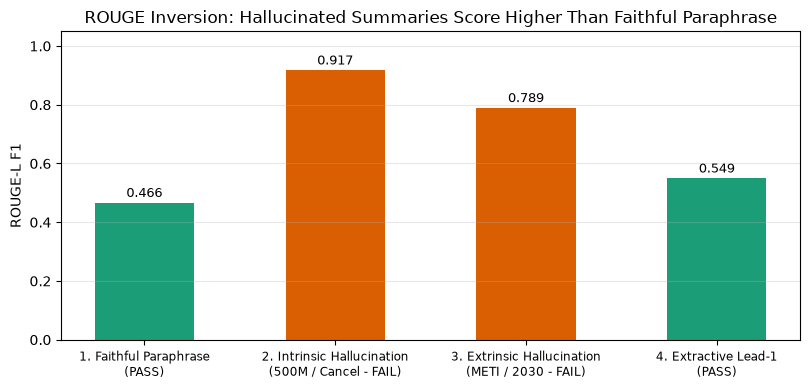

In [9]:
import re

src_article = " ".join(articles[0]["sentences"])
ref_summary = articles[0]["reference"]

candidate_summaries = [
    (
        "1. 忠実な言い換え（抽象型）",
        "国は大学やベンチャー企業に対し上限5000万円を助成する人工知能研究の支援策を来年度に始める。",
    ),
    (
        "2. 数値・極性すり替わり（内在的ハルシネーション）",
        "政府は大学やスタートアップ向けに最大5億円を支給するAI研究開発の新たな補助金制度を来年度から中止します。",
    ),
    (
        "3. 未出情報創作（外在的ハルシネーション）",
        "経済産業省は大学や米国企業向けに最大5000万円を支給するAI研究開発の新たな補助金制度を2030年から開始します。",
    ),
    (
        "4. 抽出型要約（リード 1文）",
        articles[0]["sentences"][0],
    ),
]

NEG_POLARITY = ("中止", "廃止", "見送り", "停止", "打ち切り")
ORG_ENTITIES = ("政府", "経済産業省", "総務省", "文部科学省", "大学", "スタートアップ", "ベンチャー", "米国企業", "自治体")

def check_faithfulness(src, hyp):
    src_nums = set(re.findall(r"\d+[万億千百円年件%]*", src))
    hyp_nums = set(re.findall(r"\d+[万億千百円年件%]*", hyp))
    bad_nums = sorted(hyp_nums - src_nums)

    # 同義言い換え（国~政府, ベンチャー~スタートアップ）のみ許可し、原文未出の主体を検出
    src_expanded = src.replace("政府", "政府 国").replace("スタートアップ", "スタートアップ ベンチャー")
    unseen_orgs = [o for o in ORG_ENTITIES if o in hyp and o not in src_expanded]

    pol_flip = any(w in hyp for w in NEG_POLARITY) != any(w in src for w in NEG_POLARITY)
    issues = []
    if bad_nums:
        issues.append(f"数値不一致:{','.join(bad_nums)}")
    if unseen_orgs:
        issues.append(f"未出主体:{','.join(unseen_orgs)}")
    if pol_flip:
        issues.append("極性反転")
    return ("PASS (忠実)" if not issues else "FAIL (" + " / ".join(issues) + ")", not issues)

eval_h_rows = []
for nm, hyp in candidate_summaries:
    verdict, ok_flag = check_faithfulness(src_article, hyp)
    eval_h_rows.append({
        "要約タイプ": nm,
        "ROUGE-1": round(rouge_n_f1(hyp, ref_summary, 1), 3),
        "ROUGE-2": round(rouge_n_f1(hyp, ref_summary, 2), 3),
        "ROUGE-L": round(rouge_l_f1(hyp, ref_summary), 3),
        "事実整合性判定": verdict,
        "忠実": ok_flag,
        "要約文": hyp,
    })

hall_df = pd.DataFrame(eval_h_rows)
print("参照要約:", ref_summary)
display(hall_df[["要約タイプ", "ROUGE-1", "ROUGE-2", "ROUGE-L", "事実整合性判定"]])

fig, ax = plt.subplots(figsize=(8.2, 4.0))
labels_en = [
    "1. Faithful Paraphrase\n(PASS)",
    "2. Intrinsic Hallucination\n(500M / Cancel - FAIL)",
    "3. Extrinsic Hallucination\n(METI / 2030 - FAIL)",
    "4. Extractive Lead-1\n(PASS)",
]
colors = ["#1b9e77" if ok else "#d95f02" for ok in hall_df["忠実"]]
x = np.arange(len(labels_en))
ax.bar(x, hall_df["ROUGE-L"].to_numpy(), width=0.52, color=colors)
for i, v in enumerate(hall_df["ROUGE-L"]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(labels_en, fontsize=8.5)
ax.set_ylim(0, 1.05)
ax.set_ylabel("ROUGE-L F1")
ax.set_title("ROUGE Inversion: Hallucinated Summaries Score Higher Than Faithful Paraphrase")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 第 6 節の観察とまとめ

- **ROUGE と事実忠実性の逆転現象**:
  - 内容が 100% 正確な **「1. 忠実な言い換え（抽象型）」** は「政府 → 国」「スタートアップ → ベンチャー」「開始 → 始める」と言い換えた結果、ROUGE-1 **`0.524`** / ROUGE-L **`0.466`** と低めの値になりました。
  - 一方、金額を 10 倍 (`5000万円 → 5億円`) かつ意味を真逆 (`開始 → 中止`) に歪めた **「2. 数値・極性すり替わり」** は、表層文字の大部分が参照要約と一致するため ROUGE-1 **`0.917`** / ROUGE-L **`0.917`** という極めて高いスコアを獲得してしまいます。
- **事実整合性評価の必要性（書籍 4-1-4）**: 実運用の要約評価では、ROUGE などの表層一致尺度だけに頼らず、数値・固有名詞の一致検査や自然言語推論 (NLI) モデルを用いた含意・矛盾判定、および人手による事実性評価を組み合わせることが不可欠です。